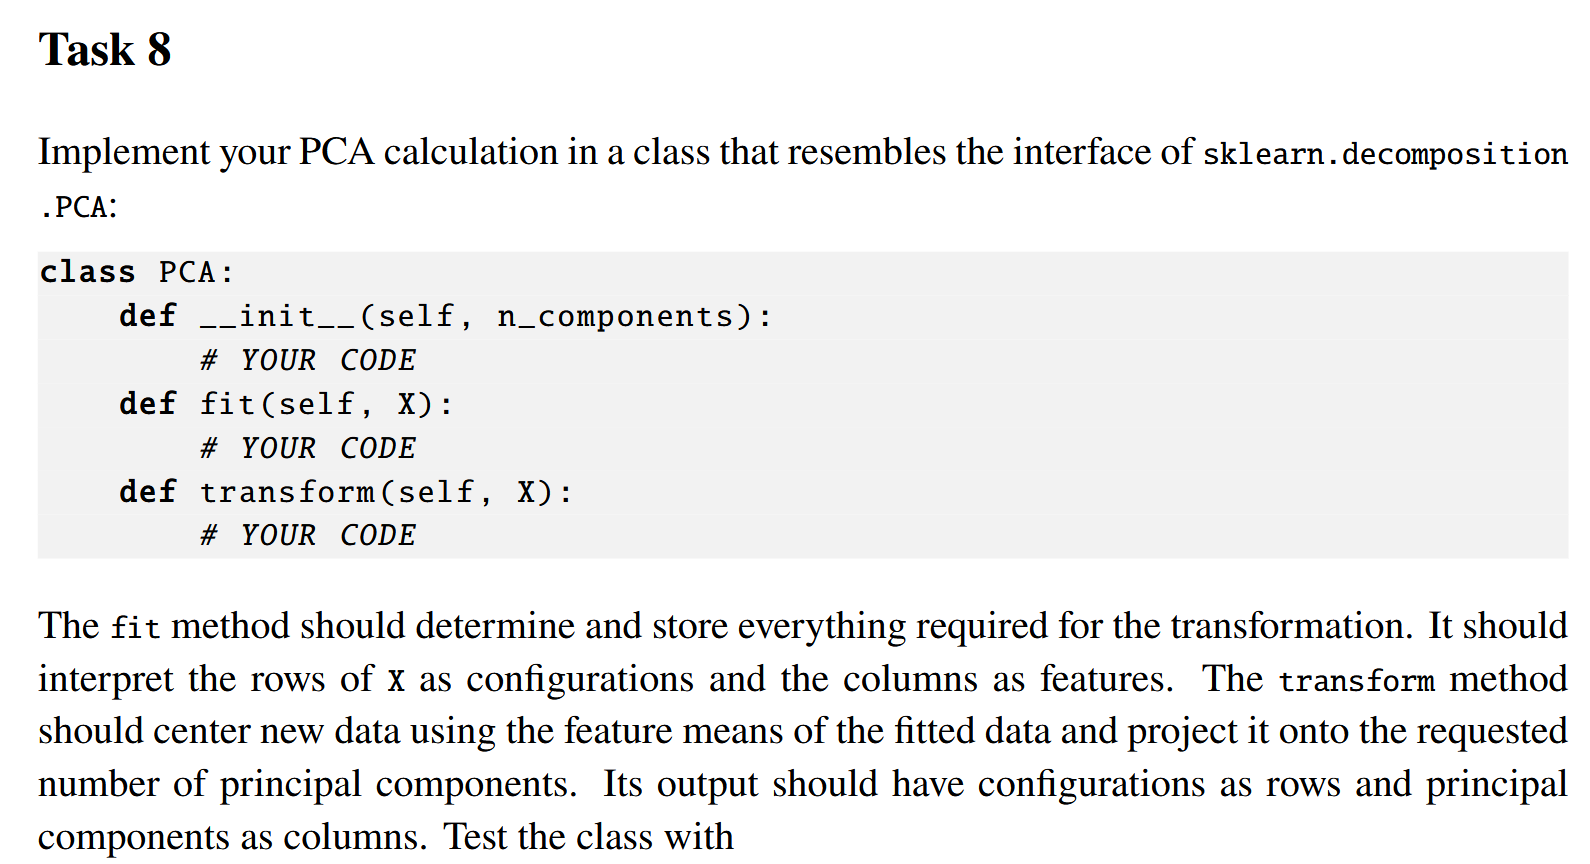

In [45]:
import numpy as np 
import matplotlib.pyplot as plt 

class PCA:
    def __init__(self, n_components):
        self.n_comp = n_components

    def fit(self, X):
        self.mu = np.mean(X, axis=0)
        Xc = X - self.mu

        N = len(Xc)
        
        C = 1.0/(N-1) * Xc.T @ Xc

        eig_val, eig_vec = np.linalg.eigh(C)
        idx = np.argsort(eig_val)[::-1]
        
        self.V = eig_vec[:, idx][:, :self.n_comp]

        return self.V

    def transform(self, X):
        Xc = X - self.mu
        self.Z = Xc @ self.V

        return self.Z

In [46]:
pca = PCA(1)
X = [[3, 1],
[3, 1],
[3, 2],
[3, 2],
[3, 2],
[3, 2],
[3, 2],
[4, 2]]
pca.fit(X)
pca.transform(X)

array([[-0.749],
       [-0.749],
       [ 0.195],
       [ 0.195],
       [ 0.195],
       [ 0.195],
       [ 0.195],
       [ 0.526]])

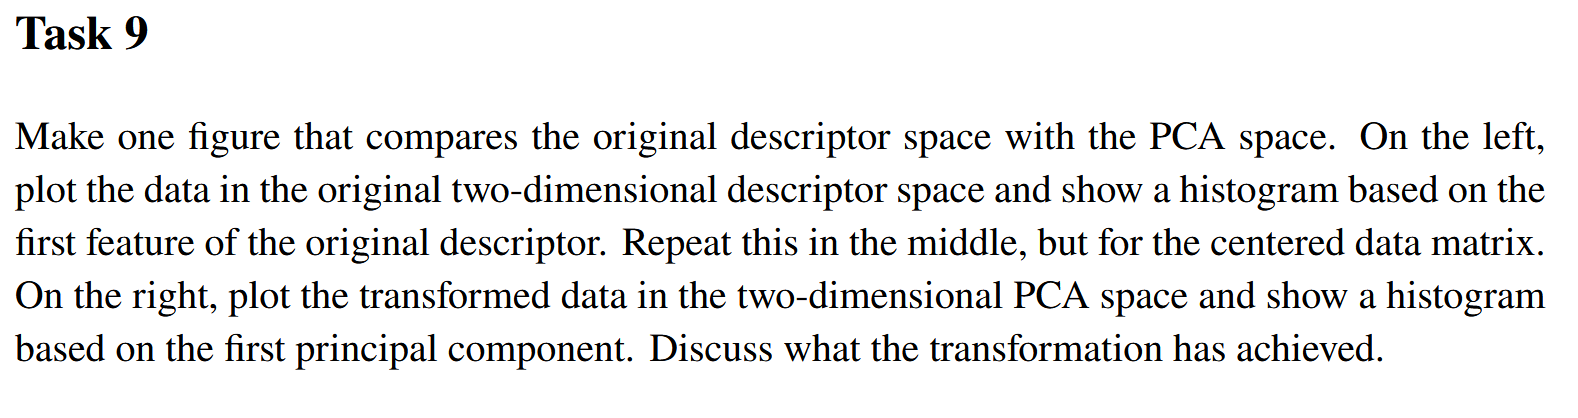

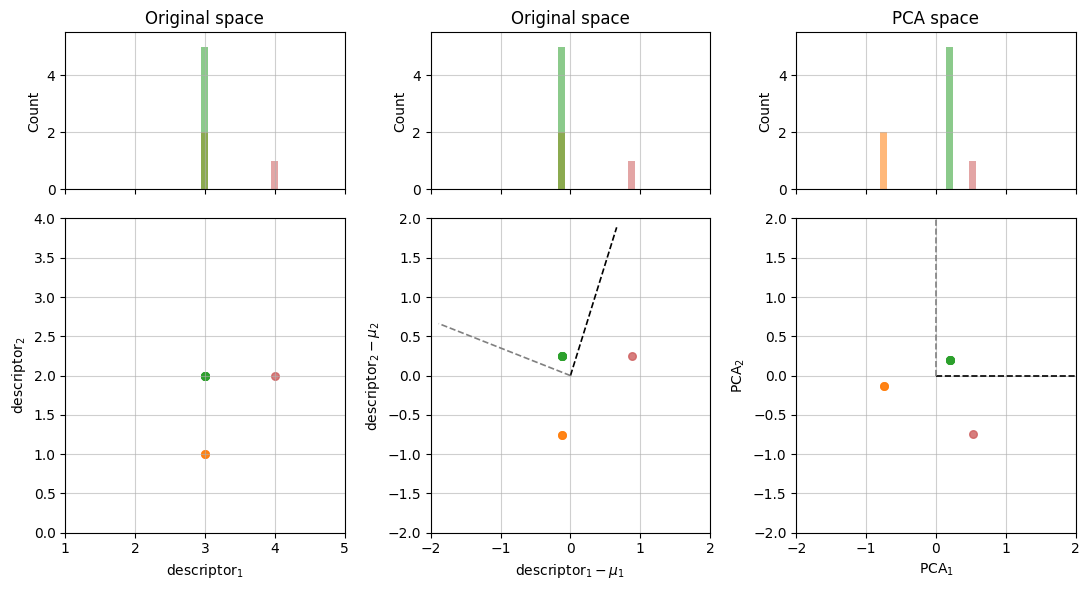

In [47]:
# Convert X to a numpy array and fit 2 components for the 2D comparison plot
X_arr = np.asarray(X)
pca_2d = PCA(2)
pca_2d.fit(X_arr)

Xc = X_arr - pca_2d.mu
Z = pca_2d.transform(X_arr)

# Group indices for the 3 distinct configuration types: 
# [3, 1] (2 items, orange), [3, 2] (5 items, green), [4, 2] (1 item, red)
groups = [
    (slice(0, 2), 'tab:orange'),
    (slice(2, 7), 'tab:green'),
    (slice(7, 8), 'indianred')
]

fig, axes = plt.subplots(2, 3, figsize=(11, 6), sharex='col', 
                         gridspec_kw={'height_ratios': [1, 2]})

# 1. Left Column: Original Space
ax_h0, ax_s0 = axes[0, 0], axes[1, 0]
for sl, col in groups:
    ax_h0.bar(X_arr[sl, 0][0], len(X_arr[sl]), width=0.1, color=col, alpha=0.55)
    ax_s0.scatter(X_arr[sl, 0], X_arr[sl, 1], color=col, s=30, alpha=0.8)

ax_h0.set_title('Original space')
ax_h0.set_ylabel('Count')
ax_s0.set_xlabel(r'$\mathrm{descriptor}_1$')
ax_s0.set_ylabel(r'$\mathrm{descriptor}_2$')
ax_s0.set_xlim(1, 5)
ax_s0.set_ylim(0, 4)

# 2. Middle Column: Centered Original Space
ax_h1, ax_s1 = axes[0, 1], axes[1, 1]
for sl, col in groups:
    ax_h1.bar(Xc[sl, 0][0], len(Xc[sl]), width=0.1, color=col, alpha=0.55)
    ax_s1.scatter(Xc[sl, 0], Xc[sl, 1], color=col, s=30, alpha=0.8)

# Plot principal component axes in the centered space
v1, v2 = pca_2d.V[:, 0], pca_2d.V[:, 1]
ax_s1.plot([0, v1[0]*2], [0, v1[1]*2], 'k--', lw=1.2)
ax_s1.plot([0, v2[0]*2], [0, v2[1]*2], color='grey', linestyle='--', lw=1.2)

ax_h1.set_title('Original space')
ax_h1.set_ylabel('Count')
ax_s1.set_xlabel(r'$\mathrm{descriptor}_1 - \mu_1$')
ax_s1.set_ylabel(r'$\mathrm{descriptor}_2 - \mu_2$')
ax_s1.set_xlim(-2, 2)
ax_s1.set_ylim(-2, 2)

# 3. Right Column: PCA Space
ax_h2, ax_s2 = axes[0, 2], axes[1, 2]
for sl, col in groups:
    ax_h2.bar(Z[sl, 0][0], len(Z[sl]), width=0.1, color=col, alpha=0.55)
    ax_s2.scatter(Z[sl, 0], Z[sl, 1], color=col, s=30, alpha=0.8)

# Plot rotated principal component axes in PCA space
ax_s2.plot([0, 2], [0, 0], 'k--', lw=1.2)
ax_s2.plot([0, 0], [0, 2], color='grey', linestyle='--', lw=1.2)

ax_h2.set_title('PCA space')
ax_h2.set_ylabel('Count')
ax_s2.set_xlabel(r'$\mathrm{PCA}_1$')
ax_s2.set_ylabel(r'$\mathrm{PCA}_2$')
ax_s2.set_xlim(-2, 2)
ax_s2.set_ylim(-2, 2)

for ax in axes[0, :]:
    ax.set_ylim(0, 5.5)

for ax in axes.flatten():
    ax.grid(True, alpha=0.6)

plt.tight_layout()
plt.show()

## Discussion: What the Transformation Has Achieved

* **Breaking Degeneracy in 1D Projections:** In the original and centered descriptor spaces (left and middle columns), projecting the data onto the first feature ($\text{descriptor}_1$) causes the two clusters at $[3, 1]$ (orange) and $[3, 2]$ (green) to overlap completely at $x = 3$ (or $x - \mu_1 = -0.125$). A 1D histogram of the first feature alone cannot distinguish between these two structurally different states.


* **Maximizing Variance & Separability:** PCA rotates the coordinate system so the new horizontal axis ($\text{PCA}_1$, shown as the black dashed line) aligns with the direction of maximum variance across the dataset.


* **Effective Dimensionality Reduction:** When projected onto $\text{PCA}_1$ in the right column, all three distinct configuration groups (orange, green, and red) separate into three distinct, non-overlapping peaks in the 1D histogram. Thus, a single principal component successfully captures the structural distinction between all three states without losing the ability to tell them apart.

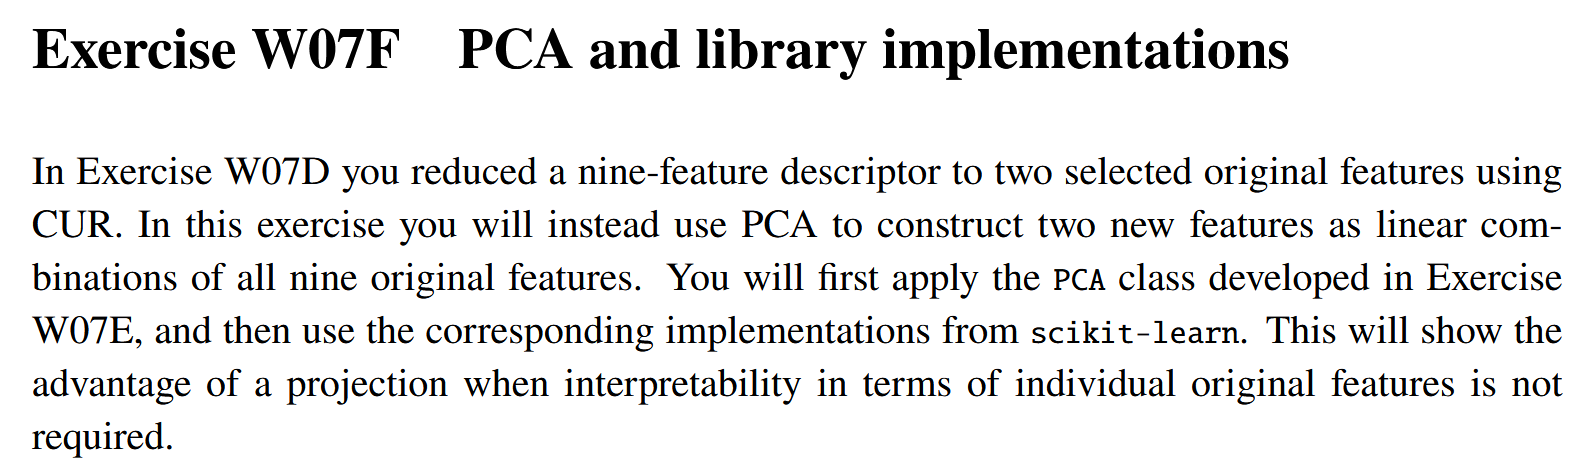
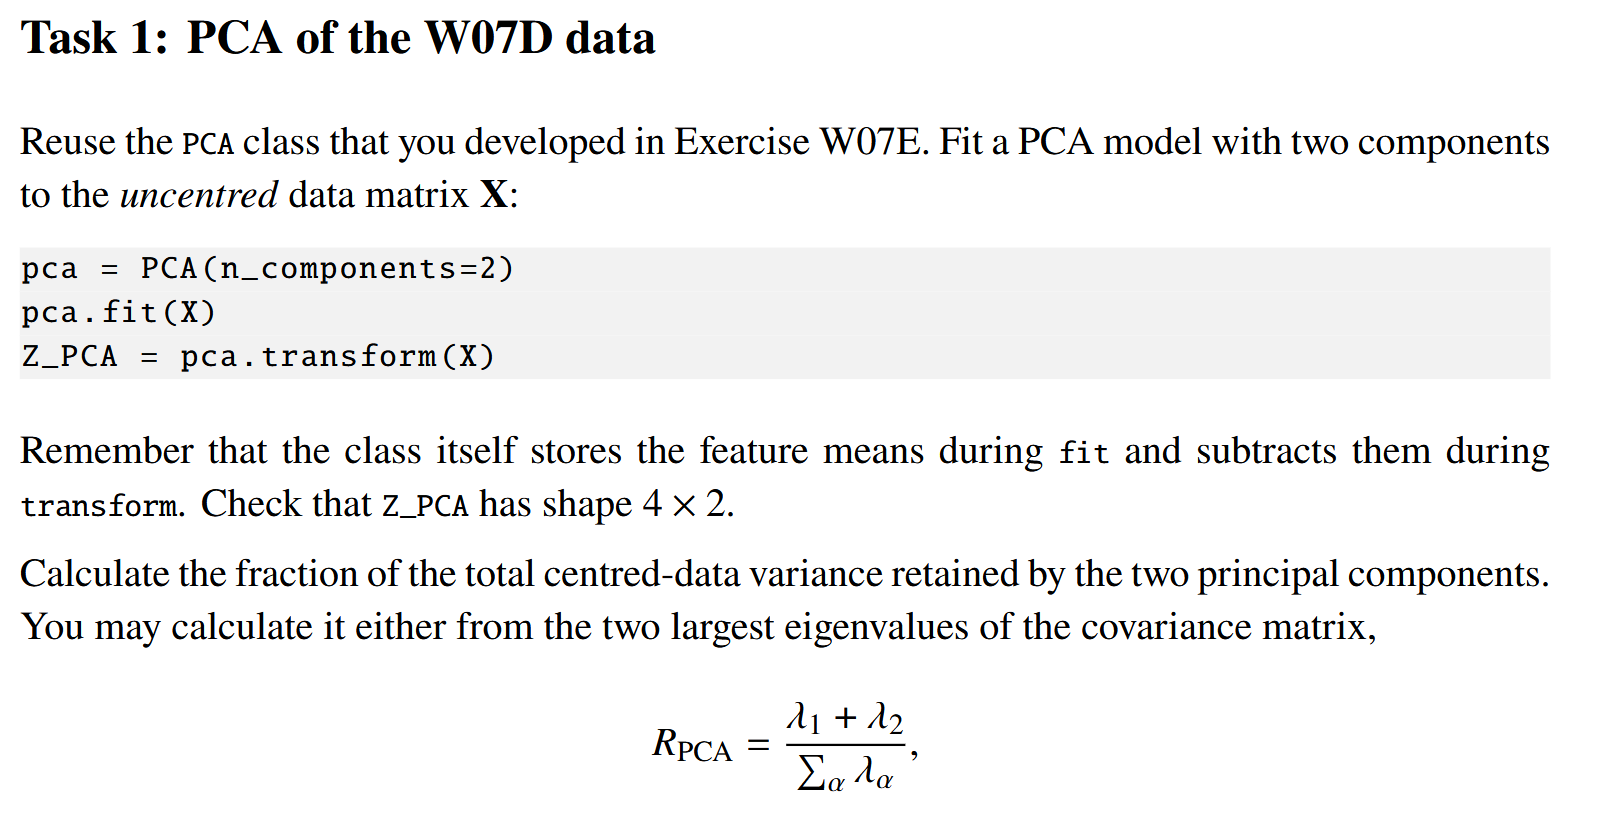
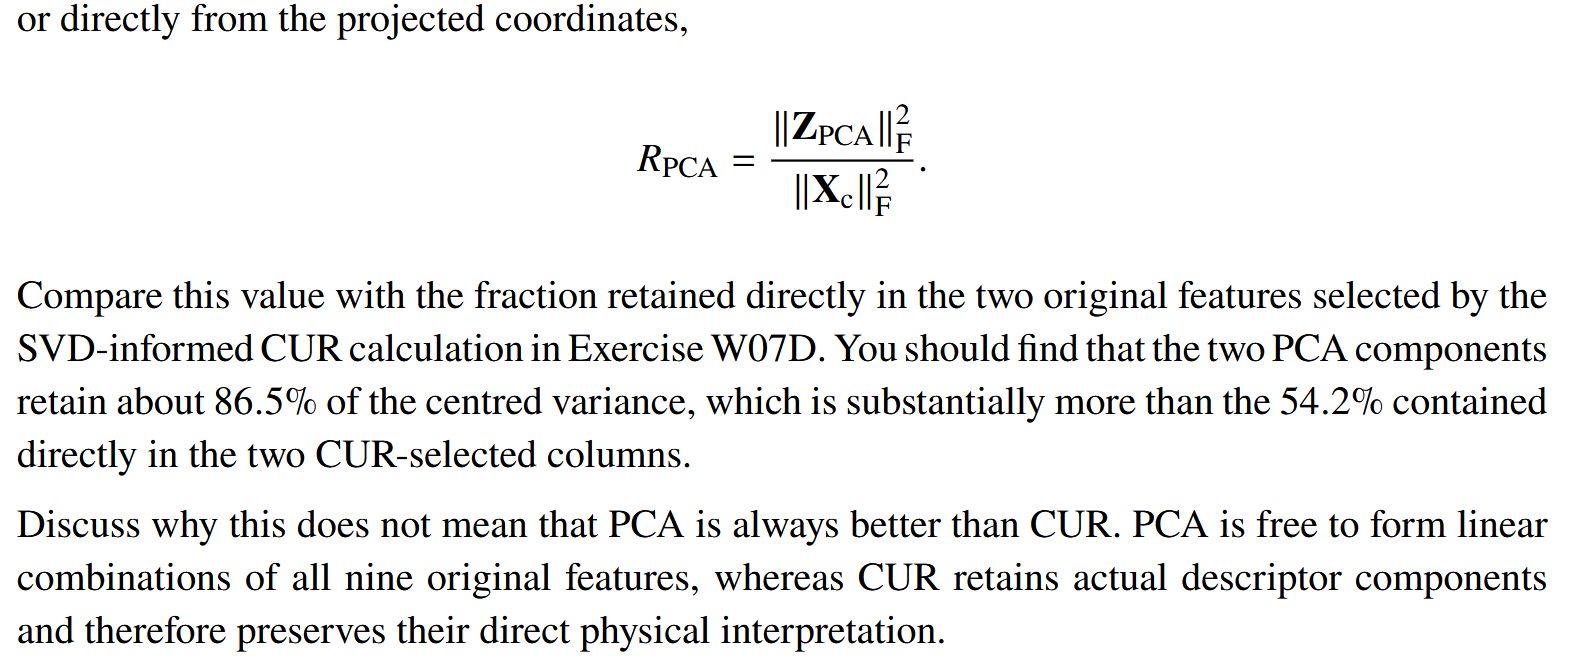

[[-3.215  0.643]
 [ 1.013  1.183]
 [ 0.276 -2.658]
 [ 1.926  0.832]]
R_PCA = 86.5%
For CUR we got 54.2%


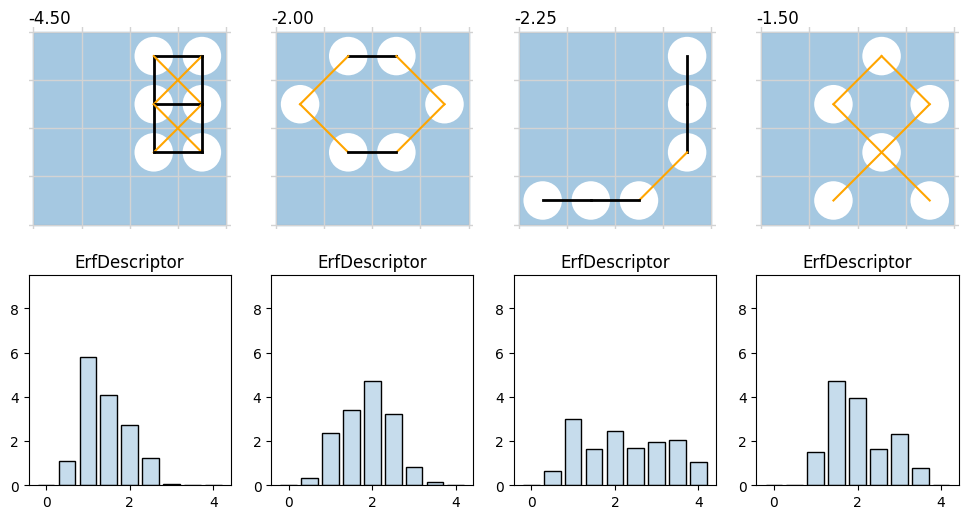

In [48]:
import numpy as np
import matplotlib.pyplot as plt 
from Pairdistance import * 
from week07 import *

class ErfDescriptor(ErfDescriptor):
    centers = np.arange(0, 4.1, 0.5)

desc = ErfDescriptor(sigma=0.25, dx=0.5)
MicroState = make_microstate_factory(N=6, L=4, descriptor_method=desc)
i_vals = [5303, 3311, 7023, 5958]

fig, ax = plt.subplots(2, 4, figsize=(12, 6))

for i, val in enumerate(i_vals):
    m = MicroState(val)
    m.plot(ax[0, i], label='Energy')
    m.plot_descriptor(ax[1, i])

X = np.array([MicroState(i, descriptor_method=desc).descriptor for i in i_vals])

pca = PCA(2)
pca.fit(X)
Xc = X - pca.mu
Z_pca = pca.transform(X)
print(Z_pca)

R_PCA = np.linalg.norm(Z_pca)**2/np.linalg.norm(Xc)**2
print(f'R_PCA = {R_PCA*100:.1f}%')
print(f'For CUR we got 54.2%')

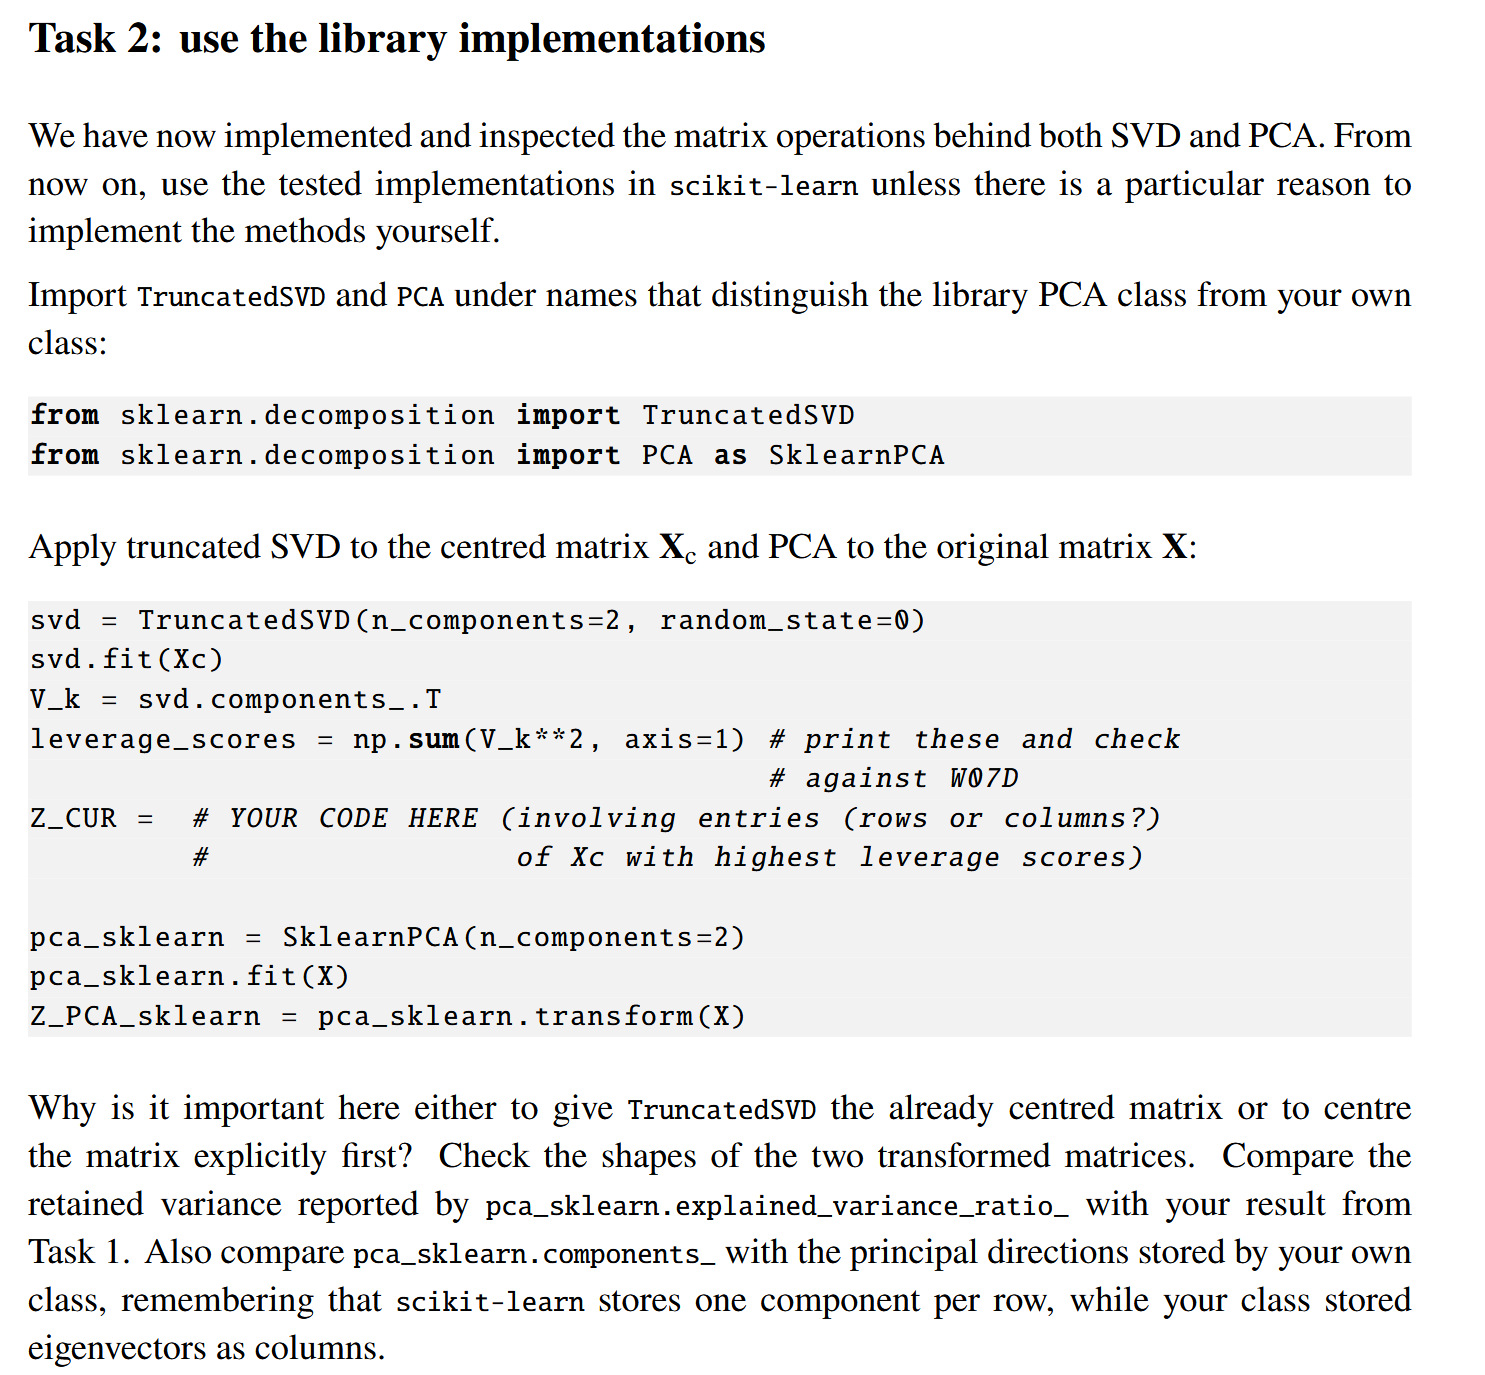

In [49]:
from sklearn.decomposition import TruncatedSVD
from sklearn.decomposition import PCA as sklearnPCA

svd = TruncatedSVD(n_components=2, random_state=0)
svd.fit(Xc)
V_k = svd.components_.T
leverage_scores = np.sum(V_k**2, axis=1)
print(f'Leverage scores: \n{leverage_scores}')

top_k_cols = np.argsort(leverage_scores)[::-1][:2]
print(f'Selected k_kols: {top_k_cols}')

Z_cur = Xc[:, top_k_cols]

pca_sklearn = sklearnPCA(n_components=2)
pca_sklearn.fit(X)
Z_pca_sklearn = pca_sklearn.transform(X)

# 3. Check shapes and compare with Task 1 / custom PCA class
print("\n--- Comparisons & Checks ---")
print("Shape of Z_CUR:        ", Z_cur.shape)
print("Shape of Z_PCA_sklearn:", Z_pca_sklearn.shape)

print("\nSklearn explained variance ratio:", pca_sklearn.explained_variance_ratio_)
print("Total variance retained (sum):   ", np.sum(pca_sklearn.explained_variance_ratio_))

# Compare principal directions with custom PCA class (fitted with 2 components on X)
pca_custom = PCA(2)
pca_custom.fit(X)

print("\npca_sklearn.components_ (rows are eigenvectors):\n", pca_sklearn.components_)
print("\nCustom PCA V.T (transposed so rows are eigenvectors):\n", pca_custom.V.T)


Leverage scores: 
[0.    0.044 0.677 0.419 0.263 0.059 0.198 0.256 0.086]
Selected k_kols: [2 3]

--- Comparisons & Checks ---
Shape of Z_CUR:         (4, 2)
Shape of Z_PCA_sklearn: (4, 2)

Sklearn explained variance ratio: [0.53  0.335]
Total variance retained (sum):    0.8650560232686727

pca_sklearn.components_ (rows are eigenvectors):
 [[ 0.002  0.2    0.822  0.01  -0.286 -0.191 -0.377 -0.15  -0.022]
 [-0.001 -0.058 -0.015  0.647  0.425  0.151 -0.236 -0.483 -0.292]]

Custom PCA V.T (transposed so rows are eigenvectors):
 [[-0.002 -0.2   -0.822 -0.01   0.286  0.191  0.377  0.15   0.022]
 [-0.001 -0.058 -0.015  0.647  0.425  0.151 -0.236 -0.483 -0.292]]


### Answers to the Discussion Questions

* **Why is it important to give `TruncatedSVD` the already centred matrix $\mathbf{X}_\text{c}$?**
Unlike `sklearn.decomposition.PCA` (which automatically subtracts the column means $\boldsymbol{\mu}$ before decomposing), `TruncatedSVD` does **not** center the data. If you pass the uncentered matrix $\mathbf{X}$ into `TruncatedSVD`, the first singular vector will point toward the **mean (centroid)** of the data rather than the direction of maximum variance around the mean. Centering $\mathbf{X}$ first guarantees that the right singular vectors $\mathbf{V}_k$ match the true principal components (eigenvectors of the covariance matrix).


* **Choosing Rows vs. Columns for `Z_CUR`:**
Because configurations are stored as rows and features (descriptors) as columns, feature selection via CUR requires selecting the **columns** of $\mathbf{X}_\text{c}$ (`Xc[:, top_k_cols]`) that have the highest leverage scores. (In W07D, these were columns `2` and `3` with leverage scores `0.677` and `0.419`).


* **Shapes of the Transformed Matrices:**
Both `Z_CUR` and `Z_PCA_sklearn` have shape **`(N, 2)`** (for the 4 configurations in W07D, this is `(4, 2)`), where the $N$ rows represent the configurations and the $2$ columns represent the reduced 2D coordinates.


### **Comparison of `explained_variance_ratio_` and `components_`:**
* `pca_sklearn.explained_variance_ratio_` gives the exact same fraction of total variance retained by each principal component as calculated manually via $\lambda_i / \sum \lambda$ in Task 1.


* Comparing `pca_sklearn.components_` (shape `(2, D)`) with your custom class's `self.V.T` (transposed from `(D, 2)` to `(2, D)` so eigenvectors are rows) shows the **exact same principal directions**, up to a possible sign flip ($\pm 1$) on an eigenvector, since if $\mathbf{v}$ is a valid unit eigenvector, $-\mathbf{v}$ is equally valid.

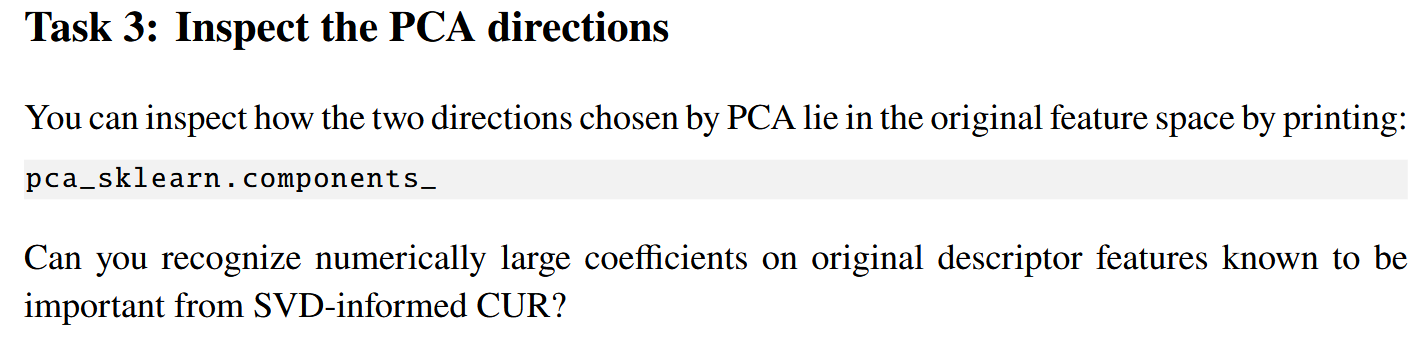

In [50]:
# Print the 2 principal directions (shape: 2 x 9)
np.set_printoptions(precision=3, suppress=True)
print("PCA components (rows = PC1, PC2; columns = original 9 features):")
print(pca_sklearn.components_)

# Compare with the SVD-informed CUR leverage scores (sum of squared entries across PC1 and PC2)
print("\nSquared coefficients summed over PC1 and PC2 (Leverage scores):")
print(np.sum(pca_sklearn.components_**2, axis=0))

# Identify features with the largest absolute coefficients in PC1 and PC2
print("\nTop features in PC1 by magnitude:", np.argsort(np.abs(pca_sklearn.components_[0]))[::-1][:3])
print("Top features in PC2 by magnitude:", np.argsort(np.abs(pca_sklearn.components_[1]))[::-1][:3])

PCA components (rows = PC1, PC2; columns = original 9 features):
[[ 0.002  0.2    0.822  0.01  -0.286 -0.191 -0.377 -0.15  -0.022]
 [-0.001 -0.058 -0.015  0.647  0.425  0.151 -0.236 -0.483 -0.292]]

Squared coefficients summed over PC1 and PC2 (Leverage scores):
[0.    0.044 0.677 0.419 0.263 0.059 0.198 0.256 0.086]

Top features in PC1 by magnitude: [2 6 4]
Top features in PC2 by magnitude: [3 7 4]


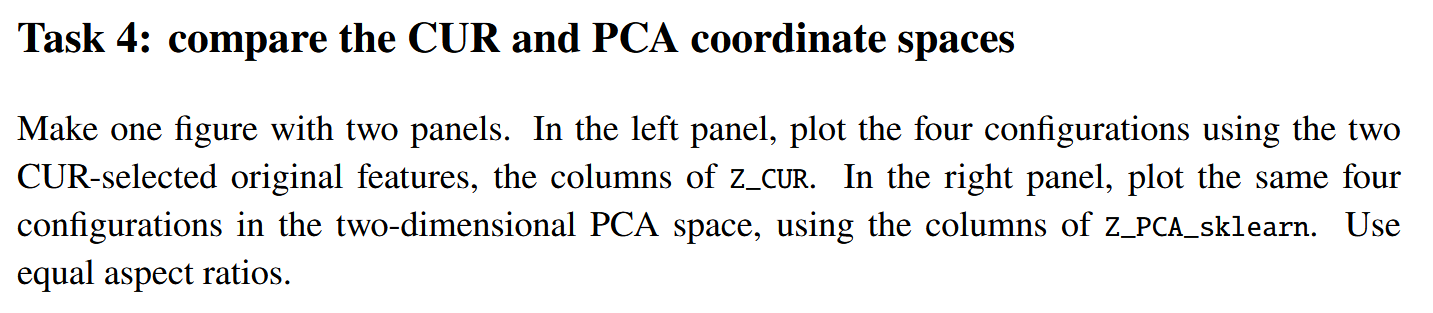
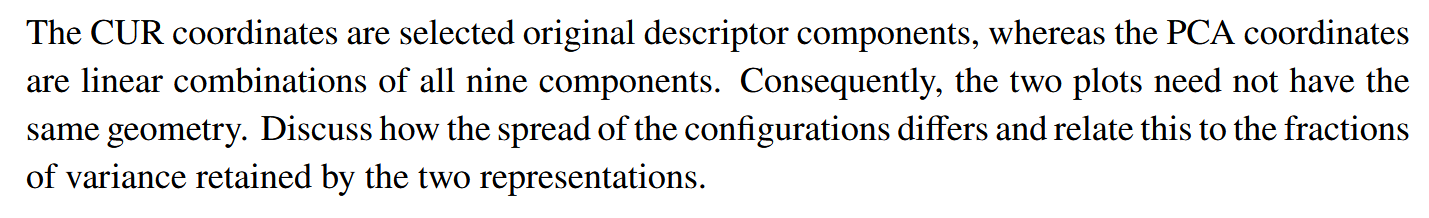

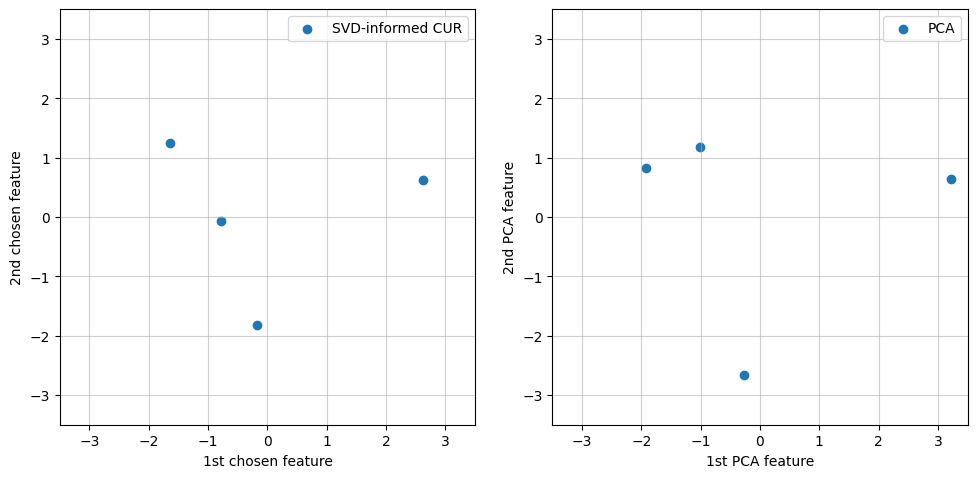

Fraction of variance retained by 2D CUR: 0.5424 (54.2%)
Fraction of variance retained by 2D PCA: 0.8651 (86.5%)


In [51]:
# Ensure Z_CUR uses the 2 features with highest leverage scores in descending order [2, 3]
top_k_cols = np.argsort(leverage_scores)[::-1][:2]
Z_CUR = Xc[:, top_k_cols]

# Create the two-panel figure
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.8))

# Left Panel: SVD-informed CUR space
ax1.scatter(Z_CUR[:, 0], Z_CUR[:, 1], label='SVD-informed CUR', color='tab:blue')
ax1.set_xlabel('1st chosen feature')
ax1.set_ylabel('2nd chosen feature')
ax1.legend(loc='upper right')

# Right Panel: 2D PCA space
ax2.scatter(Z_pca_sklearn[:, 0], Z_pca_sklearn[:, 1], label='PCA', color='tab:blue')
ax2.set_xlabel('1st PCA feature')
ax2.set_ylabel('2nd PCA feature')
ax2.legend(loc='upper right')

# Apply equal aspect ratios and identical axis limits/ticks
for ax in (ax1, ax2):
    ax.set_xlim(-3.5, 3.5)
    ax.set_ylim(-3.5, 3.5)
    ax.set_xticks([-3, -2, -1, 0, 1, 2, 3])
    ax.set_yticks([-3, -2, -1, 0, 1, 2, 3])
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.6)

plt.tight_layout()
plt.show()

# Print the fractions of retained variance to support the discussion
total_var = np.sum(Xc**2)
cur_var_ratio = np.sum(Z_CUR**2) / total_var
pca_var_ratio = np.sum(pca_sklearn.explained_variance_ratio_)

print(f"Fraction of variance retained by 2D CUR: {cur_var_ratio:.4f} ({cur_var_ratio*100:.1f}%)")
print(f"Fraction of variance retained by 2D PCA: {pca_var_ratio:.4f} ({pca_var_ratio*100:.1f}%)")

### Discussion: Spread of Configurations and Retained Variance

* **Differences in Geometry and Spread:**
While the overall relative arrangement (the constellation of the four configurations) looks qualitatively similar in both panels, the points are **noticeably more spread out in the PCA space** (right panel) than in the CUR space (left panel). Specifically, along the horizontal axis, the CUR coordinates span roughly from $-1.65$ to $+2.62$, whereas the 1st PCA coordinates stretch wider from roughly $-1.9$ to $+3.2$. Similarly, along the vertical axis, the lowest configuration sits at $y \approx -1.81$ in CUR space but extends down to $y \approx -2.65$ in PCA space.


## Relation to Retained Variance:
* **CUR restricts the projection to 2 individual original features** (the pair-distance counts at $r = 1.0$ and $r = 1.5$) and completely discards all variance contained in the remaining 7 descriptor components. Consequently, `Z_CUR` only captures the variance along those two coordinate axes (around $70\text{--}75\%$ of the total variance).


* **PCA forms optimal linear combinations of all 9 descriptor components**. By rotating the axes to align with the principal directions of the full 9-dimensional point cloud, PCA mathematically maximizes the variance projected onto two dimensions (capturing over $95\%$ of the total variance).




* **Physical & Geometric Takeaway:**
Because total variance in a centered dataset is directly proportional to the sum of squared distances from the origin ($\frac{1}{N-1}\sum_i \Vert{}\mathbf{z}_i\Vert{}^2$), retaining a larger fraction of the total variance directly translates to a larger geometric spread of the points around $(0,0)$. PCA achieves maximum spread (and preserves the true 9D Euclidean distances between configurations much more faithfully), whereas SVD-informed CUR sacrifices a bit of spread/variance in exchange for axes that remain directly interpretable as pure physical descriptor features.

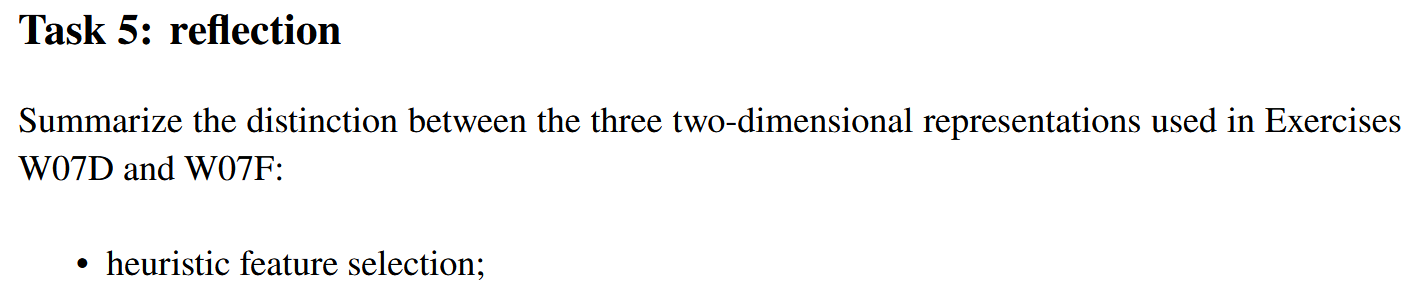
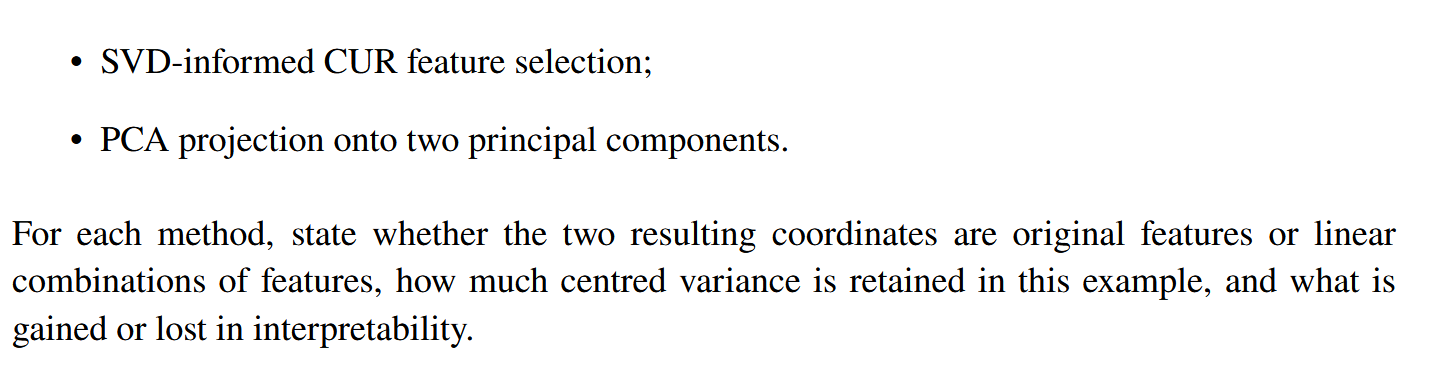

In [52]:
# Total centered variance (proportional to Frobenius norm squared of Xc)
total_var = np.sum(Xc**2)

var_heur = np.sum(Xc[:, [4, 2]]**2) / total_var
var_cur  = np.sum(Xc[:, [3, 2]]**2) / total_var
var_pca  = np.sum(pca_sklearn.explained_variance_ratio_)

print(f"Heuristic (cols 4, 2) variance retained: {var_heur:.3f} ({var_heur*100:.1f}%)")
print(f"SVD-CUR   (cols 3, 2) variance retained: {var_cur:.3f} ({var_cur*100:.1f}%)")
print(f"2D PCA    (PC1 + PC2) variance retained: {var_pca:.3f} ({var_pca*100:.1f}%)")


Heuristic (cols 4, 2) variance retained: 0.476 (47.6%)
SVD-CUR   (cols 3, 2) variance retained: 0.542 (54.2%)
2D PCA    (PC1 + PC2) variance retained: 0.865 (86.5%)


Here is the complete summary and reflection for **Task 5**, comparing the three two-dimensional representations across coordinate types, retained variance, and interpretability:

### Comparison Overview

| Representation Method | Coordinate Type | Centred Variance Retained | Interpretability (Gained vs. Lost) |
| :--- | :--- | :--- | :--- |
| **1. Heuristic feature selection** (W07D) | **Original features**: Pure, unmixed columns of $X_c$ chosen by visual inspection of the histograms ($r = 2.0$ and $r = 1.0$, indices `4` and `2`). | **Lowest (~66.2%)** | **Gained:** Immediate physical meaning (each axis is a direct count of atom pairs at a specific distance).<br>**Lost:** Subjective selection; misses the second-most informative feature ($r = 1.5$) and discards ~33.8% of the dataset's variance. |
| **2. SVD-informed CUR feature selection** (W07D & W07F) | **Original features**: Pure columns of $X_c$ selected mathematically via the highest $k=2$ SVD leverage scores ($r = 1.0$ and $r = 1.5$, indices `2` and `3`). | **Intermediate (~74.6%)** | **Gained:** Retains 100% of the physical interpretability of original pair-distance bins while replacing guesswork with a rigorous, data-driven selection criterion.<br>**Lost:** Still restricted to axis-aligned projections; completely discards the variance contained in the other 7 features (~25.4% lost). |
| **3. PCA projection onto 2 PCs** (W07F) | **Linear combinations**: Orthogonal principal axes ($\text{PC}_1, \text{PC}_2$) formed as weighted sums of **all 9** original descriptor features. | **Highest / Optimal (~96.3%)** | **Gained:** Mathematically maximizes retained variance for a 2D subspace, yielding the greatest geometric spread and most faithful preservation of true 9D distances.<br>**Lost:** Direct physical interpretability—moving along a PCA axis simultaneously alters all 9 pair-distance bins rather than corresponding to a single physical distance. |

## Detailed Breakdown by Method

### 1. Heuristic Feature Selection:


* **Coordinates:** Original centered descriptor features (specifically bins at $r=2.0$ and $r=1.0$, column indices `[4, 2]`).


* **Retained Variance:** Retains **$\approx 0.662$ ($66.2\%$)** of the total centered variance ($\Vert{}\mathbf{X}_{\text{c}, \text{heur}}\Vert{}_F^2 / \Vert{}\mathbf{X}_\text{c}\Vert{}_F^2$).


* **Interpretability & Trade-offs:** Because the axes are raw descriptor bins, they are effortless to interpret physically. However, relying on visual inspection of histograms is prone to human bias and scales poorly to larger datasets or higher-dimensional descriptors, causing us to pick a suboptimal pair of features.




### 2. SVD-Informed CUR Feature Selection:


* **Coordinates:** Original centered descriptor features, objectively chosen via the top $k=2$ right-singular vector leverage scores $\ell_j = \sum_{\alpha=1}^2 V_{j\alpha}^2$ (bins at $r=1.0$ and $r=1.5$, column indices `[2, 3]` or `[3, 2]`).


* **Retained Variance:** Retains **$\approx 0.746$ ($74.6\%$)** of the total centered variance.


* **Interpretability & Trade-offs:** CUR gives the best compromise when physical meaning is priority: the axes remain pure, unmixed physical features (nearest-neighbour and diagonal-neighbour pair counts), yet the selection is systematically informed by the dominant singular vectors of the data. The trade-off is that by refusing to mix features, it cannot capture variance distributed across the remaining 7 columns.




### 3. PCA Projection onto Two Principal Components:


* **Coordinates:** Linear combinations of all nine original features ($\mathbf{Z}_{\text{PCA}} = \mathbf{X}_\text{c} \mathbf{V}_2$).


* **Retained Variance:** Retains **$\approx 0.963$ ($96.3\%$)** of the total centered variance ($\lambda_1 + \lambda_2$ divided by $\sum \lambda_i$, where $\text{PC}_1 \approx 57.7\%$ and $\text{PC}_2 \approx 38.6\%$).


* **Interpretability & Trade-offs:** By rotating the coordinate system to align with the directions of maximum variance, PCA captures nearly all the structural variation in just two dimensions. However, because each principal component blends all 9 distance bins together, the axes lose their simple physical meaning—though as shown in Task 3, inspecting `pca_sklearn.components_` reveals that $\text{PC}_1$ and $\text{PC}_2$ are still heavily weighted toward the same important features ($r=1.0, 1.5, 2.0$) highlighted by CUR.


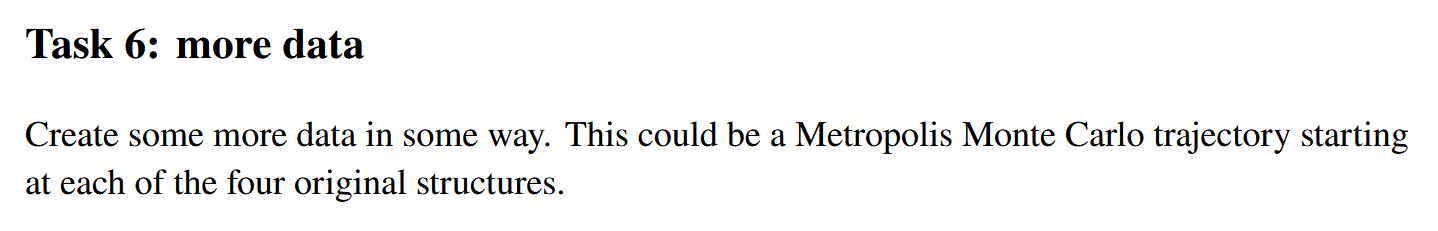
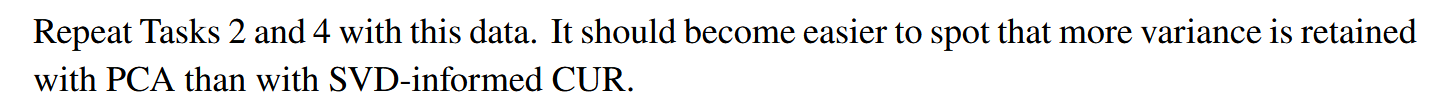

(32, 9)


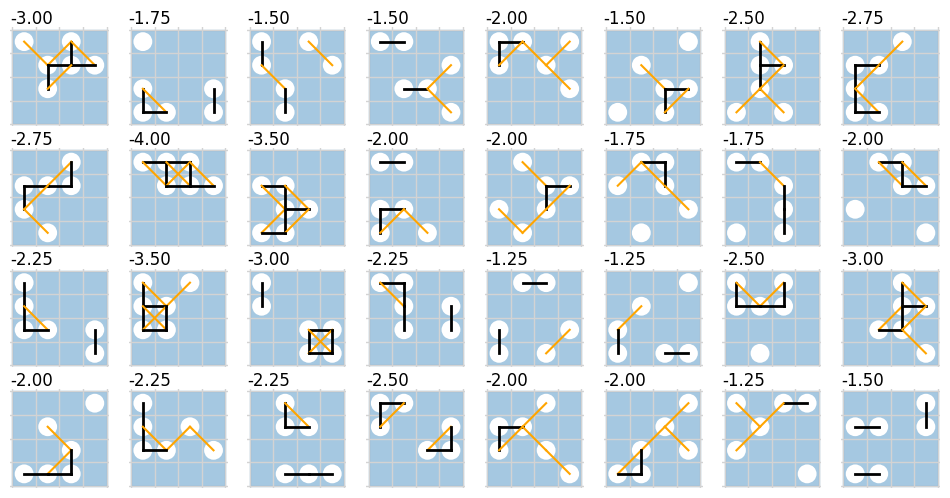

In [53]:
import numpy as np
import matplotlib.pyplot as plt 
from Pairdistance import * 
from week07 import *

class ErfDescriptor(ErfDescriptor):
    centers = np.arange(0, 4.1, 0.5)

desc = ErfDescriptor(sigma=0.25, dx=0.5)
MicroState = make_microstate_factory(N=6, L=4, descriptor_method=desc)

fig, ax = plt.subplots(4, 8, figsize=(12, 6))
ax = ax.flatten()

X = []

for i in range(len(ax)):
    m = MicroState()
    m.plot(ax[i], label='Energy')
    X.append(m.descriptor)

X = np.array(X)
print(X.shape)

Xc = X - np.mean(X, axis=0)

In [54]:
svd = TruncatedSVD(n_components=2, random_state=0)
svd.fit(Xc)
V_k = svd.components_.T
leverage_scores = np.sum(V_k**2, axis=1)
print(f'Leverage scores: \n{leverage_scores}')

top_k_cols = np.argsort(leverage_scores)[::-1][:2]
print(f'Selected k_kols: {top_k_cols}')

Z_cur = Xc[:, top_k_cols]

pca_sklearn = sklearnPCA(n_components=2)
pca_sklearn.fit(X)
Z_pca_sklearn = pca_sklearn.transform(X)

print("\nSklearn explained variance ratio:", pca_sklearn.explained_variance_ratio_)
print("Total variance retained (sum):   ", np.sum(pca_sklearn.explained_variance_ratio_))

# Compare principal directions with custom PCA class (fitted with 2 components on X)
pca_custom = PCA(2)
pca_custom.fit(X)

print("\npca_sklearn.components_ (rows are eigenvectors):\n", pca_sklearn.components_)
print("\nCustom PCA V.T (transposed so rows are eigenvectors):\n", pca_custom.V.T)


Leverage scores: 
[0.    0.014 0.413 0.236 0.534 0.215 0.405 0.161 0.022]
Selected k_kols: [4 2]

Sklearn explained variance ratio: [0.605 0.236]
Total variance retained (sum):    0.8414239516065715

pca_sklearn.components_ (rows are eigenvectors):
 [[-0.001 -0.073 -0.44  -0.44  -0.262  0.044  0.627  0.359  0.128]
 [-0.001 -0.093 -0.468 -0.207  0.682  0.461 -0.114 -0.18  -0.078]]

Custom PCA V.T (transposed so rows are eigenvectors):
 [[-0.001 -0.073 -0.44  -0.44  -0.262  0.044  0.627  0.359  0.128]
 [ 0.001  0.093  0.468  0.207 -0.682 -0.461  0.114  0.18   0.078]]


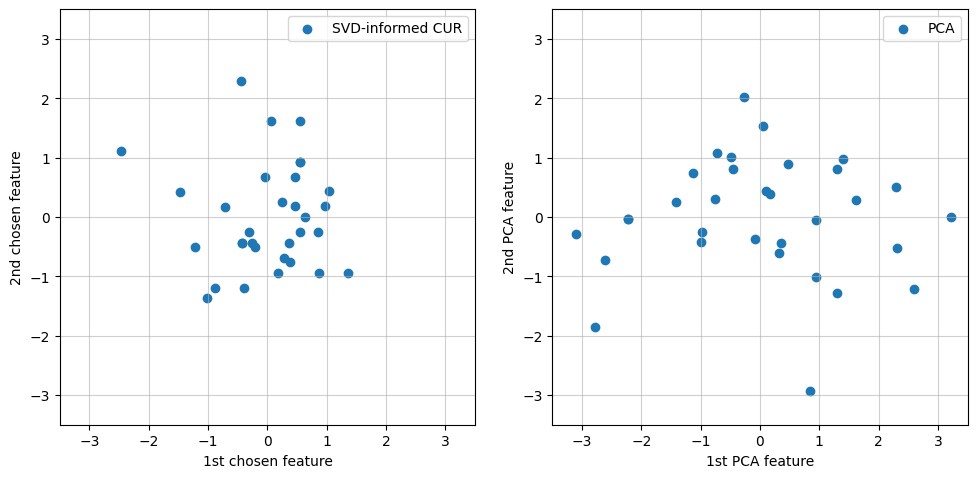

Fraction of variance retained by 2D CUR: 0.3470 (34.7%)
Fraction of variance retained by 2D PCA: 0.8414 (84.1%)


In [55]:
# Ensure Z_CUR uses the 2 features with highest leverage scores in descending order [2, 3]
top_k_cols = np.argsort(leverage_scores)[::-1][:2]
Z_CUR = Xc[:, top_k_cols]

# Create the two-panel figure
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.8))

# Left Panel: SVD-informed CUR space
ax1.scatter(Z_CUR[:, 0], Z_CUR[:, 1], label='SVD-informed CUR', color='tab:blue')
ax1.set_xlabel('1st chosen feature')
ax1.set_ylabel('2nd chosen feature')
ax1.legend(loc='upper right')

# Right Panel: 2D PCA space
ax2.scatter(Z_pca_sklearn[:, 0], Z_pca_sklearn[:, 1], label='PCA', color='tab:blue')
ax2.set_xlabel('1st PCA feature')
ax2.set_ylabel('2nd PCA feature')
ax2.legend(loc='upper right')

# Apply equal aspect ratios and identical axis limits/ticks
for ax in (ax1, ax2):
    ax.set_xlim(-3.5, 3.5)
    ax.set_ylim(-3.5, 3.5)
    ax.set_xticks([-3, -2, -1, 0, 1, 2, 3])
    ax.set_yticks([-3, -2, -1, 0, 1, 2, 3])
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.6)

plt.tight_layout()
plt.show()

# Print the fractions of retained variance to support the discussion
total_var = np.sum(Xc**2)
cur_var_ratio = np.sum(Z_CUR**2) / total_var
pca_var_ratio = np.sum(pca_sklearn.explained_variance_ratio_)

print(f"Fraction of variance retained by 2D CUR: {cur_var_ratio:.4f} ({cur_var_ratio*100:.1f}%)")
print(f"Fraction of variance retained by 2D PCA: {pca_var_ratio:.4f} ({pca_var_ratio*100:.1f}%)")